# Proyecto 3 — Mejorando algoritmos con CUDA
**CC3069 Computación Paralela y Distribuida — Universidad del Valle de Guatemala, 2026**

Clasificador del alfabeto ASL (Laboratorio 3 de Data Science): **versión secuencial original** y
**versión optimizada**, en la que la preparación de imágenes corre en **varios núcleos de CPU** y
la matemática de la red neuronal corre en la **GPU con CUDA**.

Este notebook es el entregable de código en un solo archivo. Ejecuta, fase por fase, las dos
versiones con **exactamente las mismas funciones** que los scripts del repositorio:

| Módulo | Fase | Qué contiene |
|---|---|---|
| `preparacion.py` | 1 · CPU | lectura del split, `cargar_imagen()` (JPG → uint8 64×64×3), `cargar_secuencial()` |
| `paralelo_cpu.py` | 1 · CPU | `cargar_paralelo()`: la misma carga repartida en procesos (`multiprocessing.Pool`) |
| `red.py` | 2 · red | `AlexNetASL`, `entrenar()`, `evaluar()`; reciben el dispositivo (`"cpu"` o `"cuda"`) |
| `kernels_cuda.py` | 2 · GPU | kernels propios en CUDA Python (numba-cuda) para la inferencia |
| `secuencial.py` / `optimizado.py` | ambas | las versiones medidas (3 corridas cada una, `resultados/tiempos.csv`) |

> **Tiempos oficiales.** Aquí cada fase corre **una vez**, para mostrar el flujo. Los tiempos
> del informe son la media de 3 corridas de `secuencial.py` y `optimizado.py` en la sesión
> final (`resultados/resumen.csv`), que se muestran al final del notebook.

In [1]:
import time, platform, os
import numpy as np
import torch

import preparacion as P          # fase 1: archivos e imagenes (no importa torch)
import paralelo_cpu as PC        # fase 1 en varios nucleos de CPU
import red as R                  # fase 2: la red neuronal (misma matematica en CPU y GPU)
from secuencial import anclar_a_nucleos_p

import ctypes
def todos_los_nucleos():
    # quita el anclaje: el proceso vuelve a poder usar los 24 procesadores logicos
    k32 = ctypes.windll.kernel32
    k32.GetCurrentProcess.restype = ctypes.c_void_p
    k32.SetProcessAffinityMask.argtypes = [ctypes.c_void_p, ctypes.c_size_t]
    k32.SetProcessAffinityMask(k32.GetCurrentProcess(), (1 << os.cpu_count()) - 1)

print("Python", platform.python_version(), "| torch", torch.__version__,
      "| nucleos logicos:", os.cpu_count())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible")

Python 3.12.10 | torch 2.11.0+cu128 | nucleos logicos: 24


GPU: NVIDIA GeForce RTX 5070 Laptop GPU


## 0. Datos

Split del Laboratorio 3: 22,022 imágenes de 29 clases (15,415 train / 3,303 val / 3,304 test).
Antes de medir se leen los bytes de todos los archivos para dejar la caché de disco caliente,
igual que en los scripts: así la fase 1 mide decodificación (CPU) y no velocidad del disco.

In [2]:
carpeta = P.ruta_dataset()
splits, clases = P.leer_split()
nombres = list(splits)                                   # train, val, test
todas = [r for s in nombres for r in splits[s][0]]
tamanos = [len(splits[s][0]) for s in nombres]
print({s: len(splits[s][0]) for s in nombres}, "|", len(clases), "clases")

t0 = time.perf_counter()
P.calentar_cache(carpeta, todas)
print(f"cache de disco caliente en {time.perf_counter() - t0:.1f} s (no se cronometra)")
tiempos = {}

{'train': 15415, 'val': 3303, 'test': 3304} | 29 clases


cache de disco caliente en 19.1 s (no se cronometra)


## 1. Fase 1 — Preparación de datos en CPU

### 1a. Versión secuencial original
Un `for` sobre las 22,022 imágenes en un solo núcleo: abrir el JPG, decodificar, convertir a RGB
y reducir a 64×64 (`preparacion.cargar_imagen`).

**Núcleos P y E.** Esta CPU tiene 8 núcleos de rendimiento (P) y 16 de eficiencia (E), y un
núcleo E hace este trabajo ~1.5× más lento. Para que la línea base sea el **mejor núcleo
único** (el speedup conservador), la parte secuencial se ancla a los núcleos P con
`secuencial.anclar_a_nucleos_p()`, que los detecta con la API de Windows.

In [3]:
print("anclado a los nucleos P:", anclar_a_nucleos_p())
t0 = time.perf_counter()
X_sec = P.cargar_secuencial(carpeta, todas)
tiempos[("secuencial", "carga")] = time.perf_counter() - t0
todos_los_nucleos()      # el Pool de la version paralela debe poder usar toda la CPU
print(f"carga secuencial: {tiempos[('secuencial', 'carga')]:.2f} s  ->  {X_sec.shape} {X_sec.dtype}")

anclado a los nucleos P: [0, 1, 10, 11, 12, 13, 22, 23]


carga secuencial: 19.93 s  ->  (22022, 64, 64, 3) uint8


### 1b. Versión optimizada: varios núcleos de CPU
La misma función repartida entre procesos con `multiprocessing.Pool.map`, que conserva el orden.
Se usan los procesos óptimos medidos en el barrido de la sesión final
(`paralelo_cpu.PROCESOS_OPTIMO`). La carga **se queda en la CPU**: es entrada/salida más
descompresión JPEG con mucha ramificación, que la CPU hace bien y la GPU no.

In [4]:
t0 = time.perf_counter()
X_par = PC.cargar_paralelo(carpeta, todas, procesos=PC.PROCESOS_OPTIMO)
tiempos[("optimizado", "carga")] = time.perf_counter() - t0
print(f"carga paralela con {PC.PROCESOS_OPTIMO} procesos: {tiempos[('optimizado', 'carga')]:.2f} s")
print("identica bit a bit a la secuencial:", np.array_equal(X_sec, X_par))

cortes = np.cumsum(tamanos)[:-1]
X = dict(zip(nombres, np.split(X_par, cortes)))
datos_cpu = {s: (torch.from_numpy(X[s]), torch.from_numpy(splits[s][1])) for s in nombres}

carga paralela con 4 procesos: 6.45 s
identica bit a bit a la secuencial: True


## 2. Fase 2 — Entrenamiento y evaluación de la red

`AlexNetASL` (1,372,861 parámetros), Adam con OneCycle (lr máx. 1e-3), lote de 64, **3 épocas**,
semilla 42. Las dos versiones llaman a **la misma función** `red.entrenar(modelo, X, y,
dispositivo, épocas)`; solo cambia el dispositivo.

### 2a. Versión secuencial original: CPU, 1 hilo
`torch.set_num_threads(1)`: secuencial de verdad, anclado a los núcleos P.
**Esta celda tarda unos 5 minutos.**

In [5]:
torch.set_num_threads(1)
anclar_a_nucleos_p()
torch.manual_seed(R.SEMILLA)
modelo_cpu = R.AlexNetASL(len(clases))
R.calentar(len(clases), "cpu")                       # inicializaciones perezosas, no se mide

t0 = time.perf_counter()
R.entrenar(modelo_cpu, *datos_cpu["train"], "cpu", 3)
tiempos[("secuencial", "entrenamiento")] = time.perf_counter() - t0

t0 = time.perf_counter()
acc_val, f1_val = R.evaluar(modelo_cpu, *datos_cpu["val"], "cpu")
acc_test, f1_test = R.evaluar(modelo_cpu, *datos_cpu["test"], "cpu")
tiempos[("secuencial", "evaluacion")] = time.perf_counter() - t0
print(f"CPU 1 hilo -> entrenamiento {tiempos[('secuencial', 'entrenamiento')]:.1f} s, "
      f"evaluacion {tiempos[('secuencial', 'evaluacion')]:.1f} s, "
      f"accuracy test {acc_test:.2%} (F1 macro {f1_test:.2%})")
todos_los_nucleos()
torch.set_num_threads(os.cpu_count())

  epoca 1/3: perdida=1.6654  90.4 s


  epoca 2/3: perdida=0.2381  87.1 s


  epoca 3/3: perdida=0.0340  85.8 s


CPU 1 hilo -> entrenamiento 263.3 s, evaluacion 11.9 s, accuracy test 99.61% (F1 macro 99.60%)


### 2b. Versión optimizada: GPU con CUDA

**Configuración CUDA** (parte de la separación del pipeline que pide el enunciado):
- `cudnn.benchmark = True`: cuDNN prueba algoritmos de convolución para cada forma de lote y se
  queda con el más rápido (las formas son fijas).
- `cudnn.allow_tf32 = True` (valor por defecto): las convoluciones FP32 corren en **TF32 sobre
  Tensor Cores**; las capas densas quedan en FP32 completo.
- Formato NCHW contiguo en GPU (`red.a_tensor`): con *channels_last*, BatchNorm en CUDA es 3.3×
  más lento.
- **Calentamiento** sin medir: crear el contexto CUDA, cargar cuDNN y cuBLAS y autoajustar cada
  forma de lote. Sin él, la primera época tarda ~6.5 s en vez de ~1.45 s.

In [6]:
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("highest")
prop = torch.cuda.get_device_properties(0)
print(f"{prop.name} | sm_{prop.major}{prop.minor} | {prop.multi_processor_count} SM | "
      f"{prop.total_memory / 2**30:.1f} GiB | CUDA {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}")

# Calentamiento (no se mide): una pasada completa con todas las formas de lote reales.
Xg = {s: (x.to("cuda"), y.to("cuda")) for s, (x, y) in datos_cpu.items()}
torch.manual_seed(R.SEMILLA)
m = R.AlexNetASL(len(clases))
R.entrenar(m, *Xg["train"], "cuda", 1, log=lambda *_: None)
R.evaluar(m, *Xg["val"], "cuda"); R.evaluar(m, *Xg["test"], "cuda")
del m, Xg
torch.cuda.synchronize()
print("calentamiento listo")

NVIDIA GeForce RTX 5070 Laptop GPU | sm_120 | 36 SM | 8.0 GiB | CUDA 12.8 | cuDNN 91900


calentamiento listo


**Transferencia CPU → GPU, una sola vez y en uint8** (4× menos bytes que float32). La
conversión a float y la división entre 255 ocurren después, en la GPU. Las copias son
asíncronas: `torch.cuda.synchronize()` antes de parar el cronómetro.

In [7]:
t0 = time.perf_counter()
datos_gpu = {s: (x.to("cuda"), y.to("cuda")) for s, (x, y) in datos_cpu.items()}
torch.cuda.synchronize()
tiempos[("optimizado", "transferencia")] = time.perf_counter() - t0
mib = sum(x.nbytes + y.nbytes for x, y in datos_gpu.values()) / 2**20
print(f"transferencia: {mib:.1f} MiB en {tiempos[('optimizado', 'transferencia')]:.3f} s")

torch.manual_seed(R.SEMILLA)                     # mismos pesos iniciales que la version CPU
modelo_gpu = R.AlexNetASL(len(clases))
torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
R.entrenar(modelo_gpu, *datos_gpu["train"], "cuda", 3)    # misma funcion que en CPU
tiempos[("optimizado", "entrenamiento")] = time.perf_counter() - t0

t0 = time.perf_counter()
acc_val_g, f1_val_g = R.evaluar(modelo_gpu, *datos_gpu["val"], "cuda")
acc_test_g, f1_test_g = R.evaluar(modelo_gpu, *datos_gpu["test"], "cuda")
tiempos[("optimizado", "evaluacion")] = time.perf_counter() - t0
print(f"GPU -> entrenamiento {tiempos[('optimizado', 'entrenamiento')]:.2f} s, "
      f"evaluacion {tiempos[('optimizado', 'evaluacion')]:.3f} s, "
      f"accuracy test {acc_test_g:.2%} (F1 macro {f1_test_g:.2%}), "
      f"memoria GPU max {torch.cuda.max_memory_allocated() / 2**20:.0f} MiB")

transferencia: 258.2 MiB en 0.026 s


  epoca 1/3: perdida=1.6677  1.5 s


  epoca 2/3: perdida=0.2396  1.5 s


  epoca 3/3: perdida=0.0343  1.5 s


GPU -> entrenamiento 4.39 s, evaluacion 0.242 s, accuracy test 99.64% (F1 macro 99.64%), memoria GPU max 822 MiB


### 2c. Kernels propios en CUDA Python (numba-cuda)

Para diseñar nosotros el reparto en **hilos, bloques y grids** (paso 4), la inferencia de la red
entrenada se reimplementa con 5 kernels propios: `normalizar`, `conv_bn_relu` (convolución +
BatchNorm + ReLU fusionados, con memoria compartida y 16 canales de salida por hilo),
`maxpool2`, `densa` (GEMM por *tiles* de 16×16) y `argmax`. El diseño completo está en
`docs/paso4_5_gpu.md`.

In [8]:
import kernels_cuda as KC
import math
N = 512
motor = KC.InferenciaNumba(modelo_gpu.eval())
print("grid / bloque de la primera convolucion con un lote de 512:",
      KC.grid_conv(N, 32, 64, 64))
KC.evaluar(modelo_gpu, *datos_gpu["val"])                  # compila los kernels (no se mide)
torch.cuda.synchronize()

t0 = time.perf_counter()
acc_val_k, f1_val_k = KC.evaluar(modelo_gpu, *datos_gpu["val"])
acc_test_k, f1_test_k = KC.evaluar(modelo_gpu, *datos_gpu["test"])
t_kern = time.perf_counter() - t0

with torch.no_grad():
    Xt = datos_gpu["test"][0]
    pred_cudnn = torch.cat([modelo_gpu(R.a_tensor(Xt[i:i+N], "cuda")).argmax(1) for i in range(0, len(Xt), N)])
    pred_prop = torch.cat([motor.predecir(Xt[i:i+N]) for i in range(0, len(Xt), N)])
print(f"evaluacion con kernels propios: {t_kern:.3f} s (cuDNN: {tiempos[('optimizado', 'evaluacion')]:.3f} s)")
print(f"accuracy test {acc_test_k:.2%}; predicciones iguales a cuDNN: "
      f"{(pred_cudnn == pred_prop).float().mean().item():.2%}")

grid / bloque de la primera convolucion con un lote de 512: ((1024, 4, 4), (16, 16))


C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 30 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 2 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\n

C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 30 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 2 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\hugob\.venvs\asl-cuda\Lib\site-packages\n

evaluacion con kernels propios: 0.327 s (cuDNN: 0.242 s)
accuracy test 99.64%; predicciones iguales a cuDNN: 100.00%


## 3. Comparación de este notebook (1 ejecución por fase)

In [9]:
import pandas as pd
fases = ["carga", "transferencia", "entrenamiento", "evaluacion"]
filas = []
for f in fases:
    s = tiempos.get(("secuencial", f), np.nan)
    o = tiempos.get(("optimizado", f), np.nan)
    filas.append({"fase": f, "secuencial (s)": round(s, 3), "optimizado (s)": round(o, 3),
                  "speedup": round(s / o, 1) if s == s and o == o else None})
tot_s = sum(v for (ver, _), v in tiempos.items() if ver == "secuencial")
tot_o = sum(v for (ver, _), v in tiempos.items() if ver == "optimizado")
filas.append({"fase": "total", "secuencial (s)": round(tot_s, 2), "optimizado (s)": round(tot_o, 2),
              "speedup": round(tot_s / tot_o, 1)})
print(f"accuracy test: CPU {acc_test:.2%} | GPU {acc_test_g:.2%} | GPU con kernels propios {acc_test_k:.2%}")
pd.DataFrame(filas)

accuracy test: CPU 99.61% | GPU 99.64% | GPU con kernels propios 99.64%


,fase,secuencial (s),optimizado (s),speedup
0,carga,19.926,6.450,3.1
1,transferencia,NaN,0.026,NaN
2,entrenamiento,263.328,4.390,60.0
3,evaluacion,11.944,0.242,49.3
4,total,295.200,11.110,26.6


## 4. Resultados oficiales (sesión final, media de 3 corridas)

Generados por `python resumen.py` a partir de `resultados/tiempos.csv` (3 corridas de
`secuencial.py` sin anclar —Windows lo dejó sobre todo en núcleos E—, `secuencial.py
--nucleos-p`, `secuencial.py --hilos 16`, `optimizado.py` y `optimizado.py --kernels-propios`). Las gráficas salen de
`python graficas.py`.

In [10]:
res = pd.read_csv("resultados/resumen.csv")
res = res[(res.epocas == 3) & res.version.isin(
    ["secuencial", "secuencial_nucleosP", "cpu_16hilos", "optimizado", "optimizado_numba"])]
tabla = res.pivot(index="fase", columns="version", values="media").reindex(
    ["carga", "transferencia", "entrenamiento", "evaluacion", "total"])
tabla["speedup vs 1 nucleo P"] = (tabla["secuencial_nucleosP"] / tabla["optimizado"]).round(1)
tabla["speedup vs 1 nucleo (Windows, E)"] = (tabla["secuencial"] / tabla["optimizado"]).round(1)
tabla["speedup vs CPU 16 hilos"] = (tabla["cpu_16hilos"] / tabla["optimizado"]).round(1)
tabla.round(3)

version,cpu_16hilos,optimizado,optimizado_numba,secuencial,secuencial_nucleosP,speedup vs 1 nucleo P,"speedup vs 1 nucleo (Windows, E)",speedup vs CPU 16 hilos
fase,,,,,,,,
carga,25.714,6.680,6.873,26.847,18.170,2.7,4.0,3.8
transferencia,NaN,0.104,0.129,NaN,NaN,NaN,NaN,NaN
entrenamiento,54.433,4.461,4.531,380.531,291.741,65.4,85.3,12.2
evaluacion,2.470,0.239,0.333,15.906,13.103,54.8,66.6,10.3
total,82.640,11.496,11.880,423.305,323.030,28.1,36.8,7.2


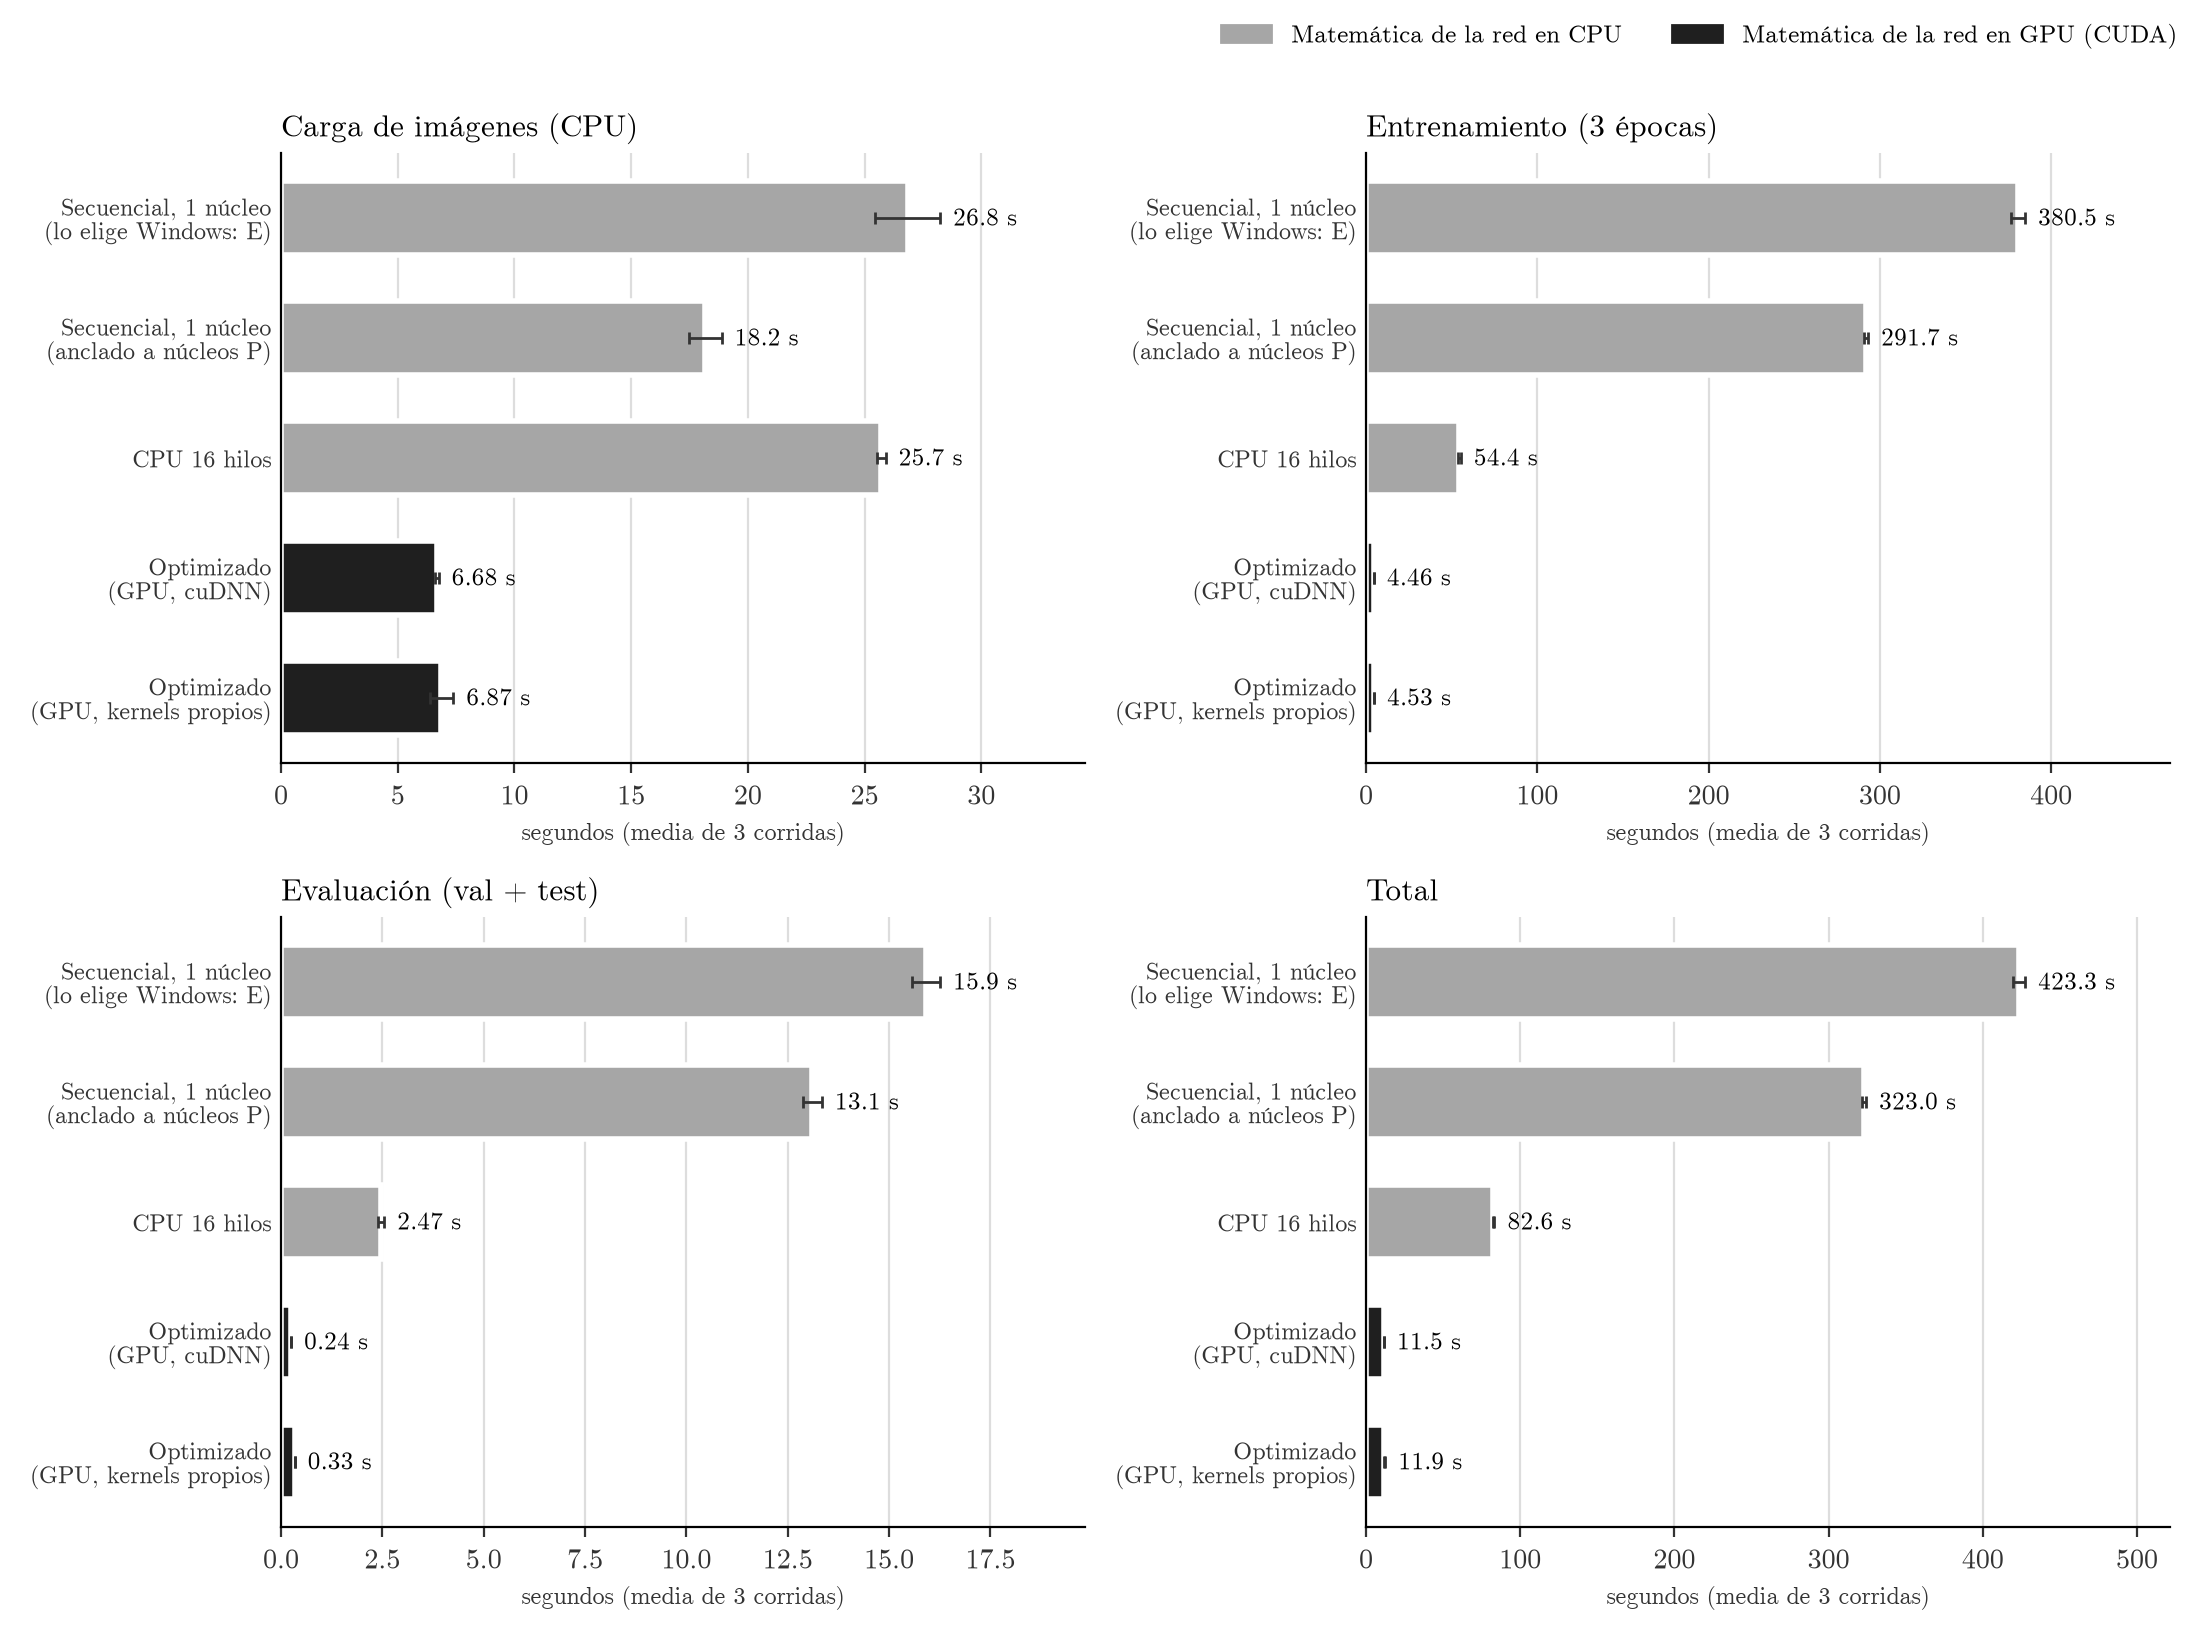

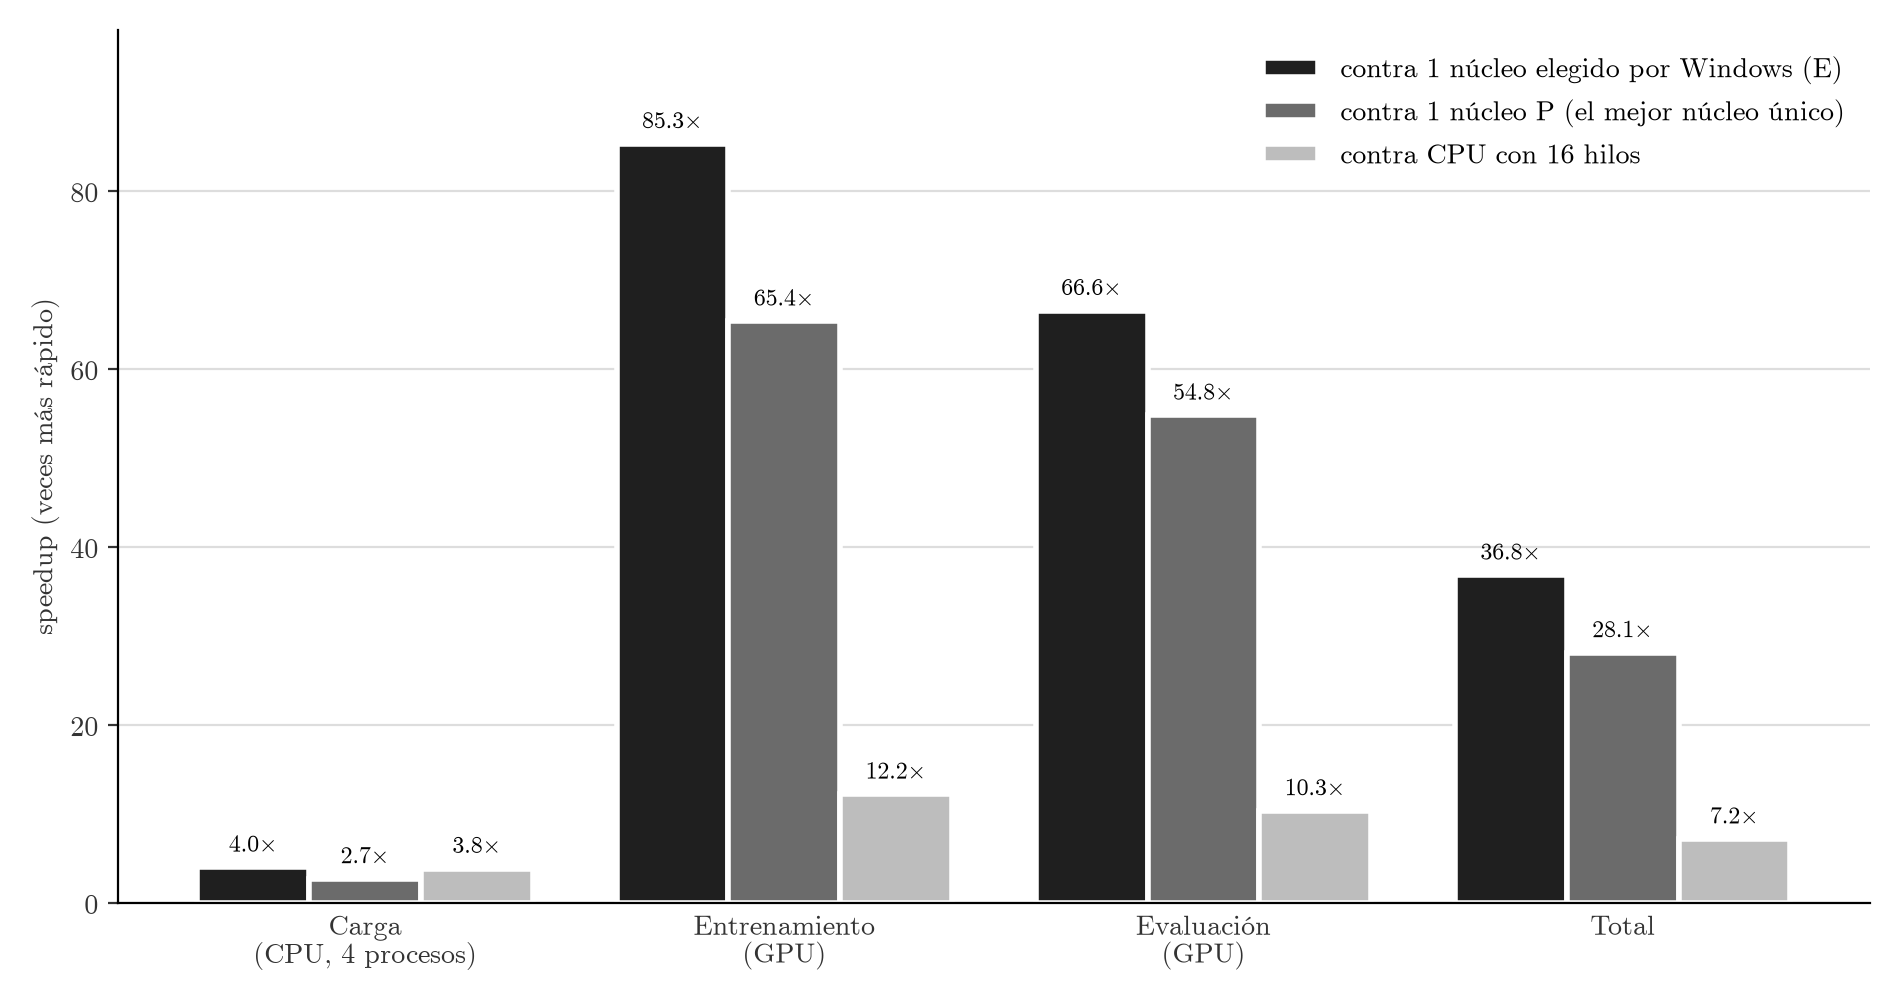

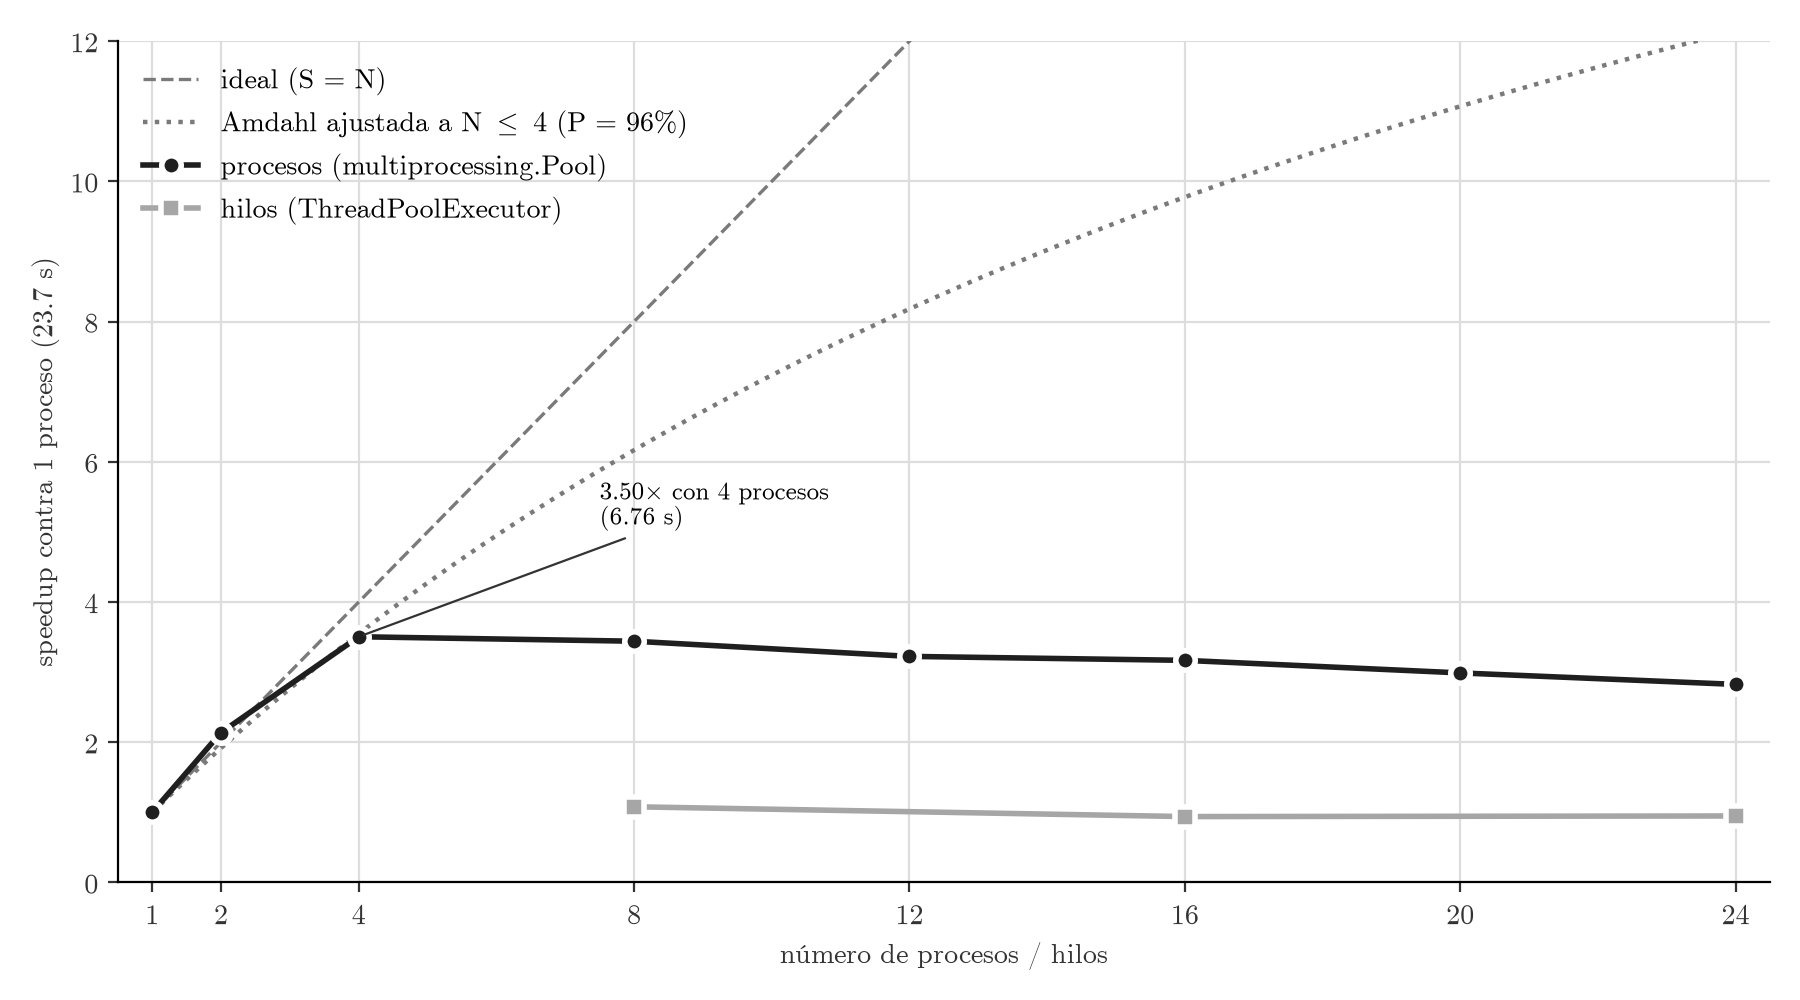

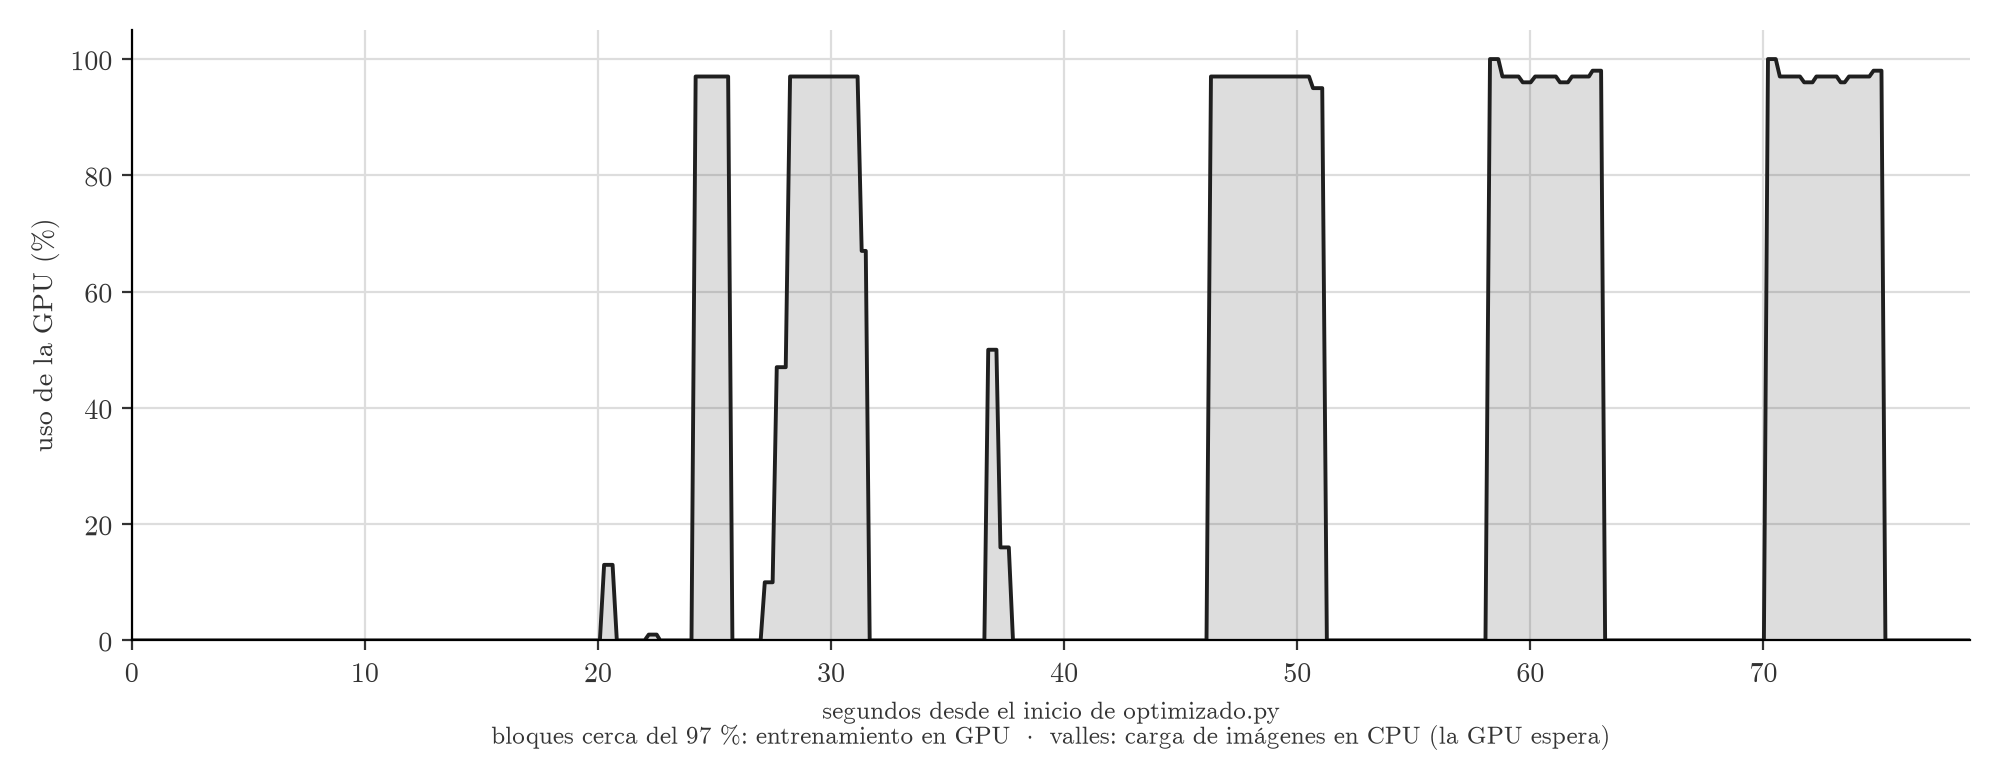

In [11]:
from IPython.display import Image, display
for g in ["tiempo_por_fase", "speedup_por_fase", "speedup_carga_cpu", "uso_gpu"]:
    display(Image(filename=f"resultados/graficas/{g}.png", width=900))